## Calculate the model variables

In [1]:
import numpy as np

def susceptibility(pre, delta_priv_pre):
    lim = 0
    if(pre > 3.5):
        s = -1
    else:
        s = 1
    if(delta_priv_pre > 0):
        lim = 6
    else:
        lim = 1

    #print("susc = " + str(s) +" (" + str(row["delta_pre_priv_"+str(sid)]) + "/(|" + str(lim) + " - " + str(row["pre_"+str(sid)]) +"|))")
    #print(row["participant_id"])
    #print(lim)
    #print(row["pre_"+str(sid)])
    #print(row["priv_"+str(sid)])
    if(delta_priv_pre!= 0):
        return (s*delta_priv_pre/np.abs(lim - pre))
    else:
        return 0

In [2]:
def conformity(pre, delta_public_pre):
    lim = 0
    if(pre > 3.5):
        s = -1
    else:
        s = 1
    if(delta_public_pre > 0):
        lim = 6
    else:
        lim = 1

    #print("susc = " + str(s) +" (" + str(row["delta_pre_priv_"+str(sid)]) + "/(|" + str(lim) + " - " + row["pre_"+str(sid)] +"|))")
    #print(lim)
    #print(row["pre_"+str(sid)])
    if(delta_public_pre!= 0):
        return (s*int(delta_public_pre)/np.abs(lim - pre))
    else:
        return 0

### __Susceptibility__

In [3]:
import json
import pandas as pd
import numpy as np

with open("./data_final.json") as f:
    data = json.load(f)

agents = ["robots", "virtuals", "articles"]
topics = ["robot_related", "socio-economic"]
stmt_ids = [1, 2, 3, 4, 5, 6]


results = []



for ag in agents:
    susc = 0
    total = 0
    for sid in stmt_ids:
    
        
            
        for row in data:
            
                if(row["agents_"+str(sid)] == ag and row["condition_"+str(sid)] == "all_disagree"):
                    susc += susceptibility(int(row["pre_"+str(sid)]), int(row["delta_pre_priv_"+str(sid)]))
                    total += 1
    
    susc = susc/(total*4)
    entry = {
        "agent": ag,
        "susceptibility": np.round(susc, decimals=3),
        "n": total
    }
    results.append(entry)
    print(entry)

with open("./susceptibility_results.json", "w") as f:
    json.dump(results, f, indent=2)                    
                                                               
                    

{'agent': 'robots', 'susceptibility': np.float64(0.03), 'n': 130}
{'agent': 'virtuals', 'susceptibility': np.float64(0.032), 'n': 130}
{'agent': 'articles', 'susceptibility': np.float64(0.036), 'n': 130}


### __Weight__

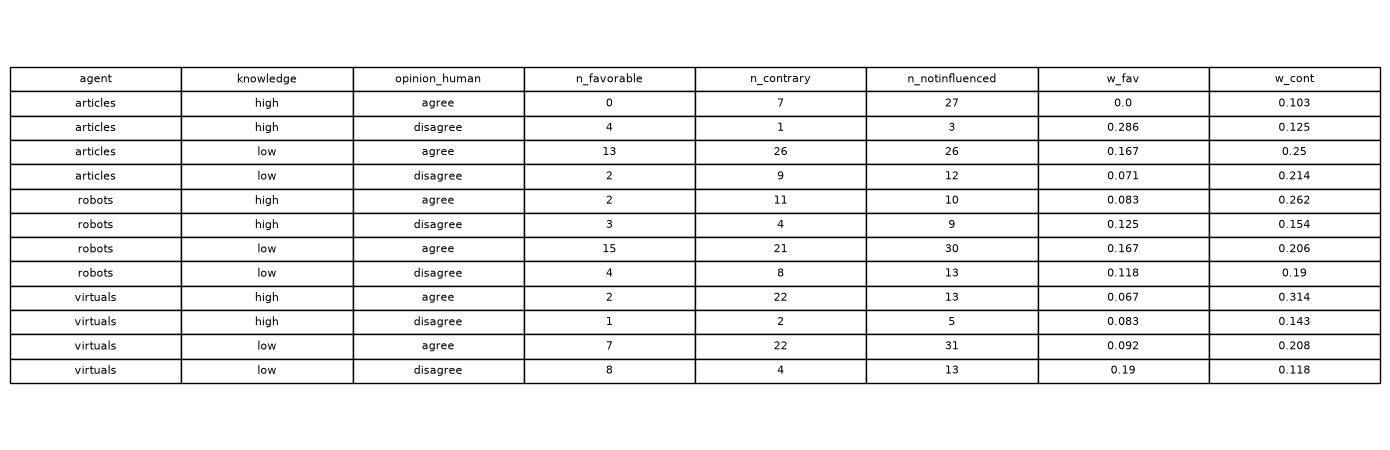

390


In [4]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


with open("./data_final.json") as f:
    data = json.load(f)

agents = ["robots", "virtuals", "articles"]
topics = ["robot_related", "socio-economic"]
knowledge = ["low", "high"]
opinion_human = ["agree", "disagree"]
opinion_agent = ["favorable", "contrary"]

dic = {}
n_total = 0

stmt_ids = [1, 2, 3, 4, 5, 6]

rows = []

    
    
    
for ag in agents:
    for kn in knowledge:
        for oh in opinion_human:   
            

            n_favorable = 0
            n_notinfluenced = 0
            n_contrary = 0
            
            for sid in stmt_ids:

                for row in data:
                
                    if(row["agents_"+str(sid)] == ag and row["condition_"+str(sid)] == "half_disagree"):
                        
                        
                        if(kn == "low" and int(row["knowledge_"+str(sid)]) <= 4):
        
                            if(int(row["pre_"+str(sid)]) < 3.5 and oh == "disagree"):
                                if int(row["delta_pre_priv_"+str(sid)]) < 0:
                                    n_favorable +=1
                                elif int(row["delta_pre_priv_"+str(sid)]) > 0:
                                    n_contrary +=1
                                else:
                                    n_notinfluenced +=1
                            elif(int(row["pre_"+str(sid)]) >= 3.5 and oh == "agree"):
                                if int(row["delta_pre_priv_"+str(sid)]) > 0:
                                    n_favorable +=1
                                elif int(row["delta_pre_priv_"+str(sid)]) < 0:
                                    n_contrary +=1
                                else:
                                    n_notinfluenced +=1
        
                        elif(kn == "high" and int(row["knowledge_"+str(sid)]) > 4):
                            if(int(row["pre_"+str(sid)]) < 3.5 and oh == "disagree"):
                                
                                if int(row["delta_pre_priv_"+str(sid)]) < 0:
                                    n_favorable +=1
                                elif int(row["delta_pre_priv_"+str(sid)])  > 0:
                                    n_contrary +=1
                                else:
                                    n_notinfluenced +=1
                            elif(int(row["pre_"+str(sid)]) >= 3.5 and oh == "agree"):
                                
                                if int(row["delta_pre_priv_"+str(sid)]) > 0:
                                    n_favorable +=1
                                elif int(row["delta_pre_priv_"+str(sid)]) < 0:
                                    n_contrary +=1
                                else:
                                    n_notinfluenced +=1
            if(n_favorable+n_notinfluenced !=0):
                w_fav = n_favorable/(2*(n_favorable+n_notinfluenced))
            else:
                w_fav = 0
            if(n_contrary+n_notinfluenced != 0):
                w_cont = n_contrary/(2*(n_contrary+n_notinfluenced))
            else:
                w_cont = 0
    
            n_total += n_contrary + n_notinfluenced + n_favorable
    
            entry = {
                "agent": ag,
                
                "knowledge": kn,
                "opinion_human": oh,
                "n_favorable": n_favorable,
                "n_contrary": n_contrary,
                "n_notinfluenced": n_notinfluenced,
                "w_fav": w_fav,
                "w_cont": w_cont
            }
        
            rows.append(entry)
    
df = pd.DataFrame(rows)
df = df.sort_values(by=["agent", "knowledge", "opinion_human"]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, len(df) * 0.3 + 1))
ax.axis("off")

tabela = ax.table(
    cellText=df.round(3).values,
    colLabels=df.columns,
    loc="center",
    cellLoc="center"
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(8)
tabela.scale(1, 1.2)

plt.tight_layout()
plt.show()

print(n_total)

with open("./weights_results.json", "w") as f:
    json.dump(rows, f, indent=2)    

### __Conformity__

In [5]:
import json
import pandas as pd
import numpy as np

with open("./data_final.json") as f:
    data = json.load(f)

agents = ["robots", "virtuals", "articles"]
topics = [ "robot_related", "socio-economic"]
stmt_ids = [1, 2, 3, 4, 5, 6]

results = []

    
    
for ag in agents:

    conf = 0
    total = 0
    for sid in stmt_ids:
        for row in data:
            
            if(row["agents_"+str(sid)] == ag  and row["condition_"+str(sid)] == "all_disagree"):
                conf += conformity(int(row["pre_"+str(sid)]), int(row["delta_pre_public_"+str(sid)]))
                total += 1

    conf = conf/(4*total)
    entry = {
        "agent": ag,
        "conformity": np.round(conf, decimals=3),
        "n": total
    }
    results.append(entry)
    print(entry)
            
with open("./conformity_results.json", "w") as f:
    json.dump(results, f, indent=2)
                    
                                                               
                    

{'agent': 'robots', 'conformity': np.float64(0.037), 'n': 130}
{'agent': 'virtuals', 'conformity': np.float64(0.048), 'n': 130}
{'agent': 'articles', 'conformity': np.float64(0.041), 'n': 130}


### __Noise__

In [7]:
import json
import pandas as pd
import numpy as np


with open("./data_final.json") as f:
    data = json.load(f)

agents = ["robots", "virtuals", "articles"]
topics = [ "robot_related", "socio-economic"]
stmt_ids = [1, 2, 3, 4, 5, 6]


conformities = []

for sid in stmt_ids:
    for row in data:
        if row["condition_" + str(sid)] == "all_disagree":
            conf = conformity(
                int(row["pre_" + str(sid)]),
                int(row["delta_pre_public_" + str(sid)])
            ) / 4

            conformities.append(conf)

mean = np.mean(conformities)
std = np.std(conformities, ddof=1)

print("Conf Mean:", round(mean, 3))
print("Conf Standard deviation:", round(std, 3))

suscs = []

for sid in stmt_ids:
    for row in data:
        if row["condition_" + str(sid)] == "all_disagree":
            susc = susceptibility(
                int(row["pre_" + str(sid)]),
                int(row["delta_pre_priv_" + str(sid)])
            ) / 4

            suscs.append(susc)

mean = np.mean(suscs)
std = np.std(suscs, ddof=1)

print("Susc Mean:", round(mean, 3))
print("Susc Standard deviation:", round(std, 3))




Conf Mean: 0.042
Conf Standard deviation: 0.087
Susc Mean: 0.033
Susc Standard deviation: 0.08


## EPO Model

### Equations

In [10]:
import numpy as np

def priv(opinion, last_opinion, agents_opinion, susc, weights, noise_susc, noise_w):
    n = len(agents_opinion)
    noise_w = np.random.normal(0, noise_w)
    noise_susc = np.random.normal(0, noise_susc)
    delta = sum(
        max(-1, min(1,s+noise_susc)) * ((1 - max(0, min(1,w+noise_w))) * opinion + max(0, min(1,w+noise_w)) * a - last_opinion)
        for s, w, a in zip(susc, weights, agents_opinion)
    ) / n
    return last_opinion + delta


def public(opinion, agents_opinion, conf, noise_range):
    n = len(agents_opinion)
    noise_conf = np.random.normal(0, noise_range)
    delta = sum(
        max(-1, min(1,c+noise_conf)) * (a - opinion)
        for c, a in zip(conf, agents_opinion)
    ) / n
    return opinion + delta

### Aux Functions and classes

In [15]:
import numpy as np

class Human:
    def __init__(self, initial_opinion, knlowedge):
        self.inital_opinion = initial_opinion
        self.previous_opinion = initial_opinion
        self.private_opinion = initial_opinion
        self.public_opinion = initial_opinion
        self.knowledge = knlowedge

    def update_previous(self, prev):
        self.previous_opinion = prev
    
    def update_priv(self, priv):
        self.private_opinion = priv

    def update_public(self, pub):
        self.public_opinion = pub

    def get_priv(self):
        return self.private_opinion

    def get_previous(self):
        return self.previous_opinion

    def get_initial(self):
        return self.inital_opinion

    def get_public(self):
        return self.public_opinion

    def get_knowledge(self):
        return self.knowledge

    
        

class Agent:
    def __init__(self, opinion, type_inf, susc, conf):
        self.type_inf = type_inf
        self.susc = susc
        self.conf = conf
        self.opinion = opinion

    def get_opinion(self):
        return self.opinion

    def get_type(self):
        return self.type_inf

    def get_susc(self):
        return self.susc

    def get_conf(self):
        return self.conf
    
    

class Population:
    def __init__(self, population_distribution, weights, susc, conf, noise_susc, noise_conf, noise_w):
        self.population_humans = []
        self.population_influencer = []
        self.weights = weights
        self.susc = susc
        self.conf = conf
        self.noise_susc = noise_susc
        self.noise_conf = noise_conf
        self.noise_w = noise_w

        for _ in range(population_distribution["humans"]["number"]):
            opinion = np.random.choice(list(population_distribution["humans"]["opinions"].keys()), p=list(population_distribution["humans"]["opinions"].values()))
            kn = np.random.choice(list(population_distribution["humans"]["knowledge"].keys()), p=list(population_distribution["humans"]["knowledge"].values()))

            human = Human(int(opinion), kn)
            self.population_humans.append(human)

        
        for _ in range(population_distribution["influencers"]["articles"]["number"]):
            opinion = np.random.choice(list(population_distribution["influencers"]["articles"]["opinions"].keys()), p=list(population_distribution["influencers"]["articles"]["opinions"].values()))
            s = float(susc["articles"]) 
            r = float(conf["articles"])
            new = Agent(int(opinion), "article", s, r)
            self.population_influencer.append(new)
        for _ in range(population_distribution["influencers"]["virtuals"]["number"]):
            opinion = np.random.choice(list(population_distribution["influencers"]["virtuals"]["opinions"].keys()), p=list(population_distribution["influencers"]["virtuals"]["opinions"].values()))
            s = float(susc["virtuals"]) 
            r = float(conf["virtuals"])
            new = Agent(int(opinion), "virtual", s, r)
            self.population_influencer.append(new)
        for _ in range(population_distribution["influencers"]["robots"]["number"]):
            opinion = np.random.choice(list(population_distribution["influencers"]["robots"]["opinions"].keys()), p=list(population_distribution["influencers"]["robots"]["opinions"].values()))
            s = float(susc["robots"]) 
            r = float(conf["robots"])
            new = Agent(int(opinion), "robot", s, r)
            self.population_influencer.append(new)

        self.agents_public_opinions = []
        self.agents_confs = []
        self.agents_susc = []
        for i in self.population_influencer:
            self.agents_public_opinions.append(i.get_opinion())
            self.agents_confs.append(i.get_conf())
            self.agents_susc.append(i.get_susc())
        


            
    def step(self):
        for h in self.population_humans:

            h.update_public(max(1,min(6,public(h.get_priv(), self.agents_public_opinions, self.agents_confs, self.noise_conf))))

        for h in self.population_humans:

            weights = []
             
            for i in self.population_influencer:
                
                inf_human_opinion = ""
                #print(h.get_priv())
                #print(i.get_opinion())
                if(h.get_priv() >= 3.5 and i.get_opinion() >= 3.5):
                    inf_human_opinion = "w_fav"
                elif(h.get_priv() >= 3.5 and i.get_opinion() < 3.5):
                    inf_human_opinion = "w_cont"
                elif(h.get_priv() < 3.5 and i.get_opinion() >= 3.5):
                    inf_human_opinion = "w_cont"
                elif(h.get_priv() < 3.5 and i.get_opinion() < 3.5):
                    inf_human_opinion = "w_fav"

                human_opinion = ""
               
                if(h.get_priv() >= 3.5):
                    human_opinion = "agree"
                else:
                    human_opinion = "disagree"

                #print(human_opinion)
                #print(inf_human_opinion)
                    
                
                weights.append(self.weights[i.get_type()+"s"][h.get_knowledge()][human_opinion][inf_human_opinion])               
            
            
            h.update_priv(max(1,min(6,priv(h.get_priv(), h.get_previous(), self.agents_public_opinions, self.agents_susc, weights, self.noise_susc, self.noise_w))))
            h.update_previous(h.get_priv())
                

    def get_public_opinions(self):
        opinions = []
        for h in self.population_humans:
            opinions.append(h.get_public())
            
        return opinions
    
    def get_priv_opinions(self):
        opinions = []
        for h in self.population_humans:
            opinions.append(h.get_priv())
            
        return opinions
        

        

In [16]:
import json

with open("./weights_results.json") as f:
    weights_rows = json.load(f)

with open("./conformity_results.json") as f:
    conformity_rows = json.load(f)

with open("./susceptibility_results.json") as f:
    susceptibility_rows = json.load(f)


weights = {}
conf = {}
susc = {}

for row in weights_rows:
   
    ag = row["agent"]
    kn = row["knowledge"]
    oh = row["opinion_human"]

    weights.setdefault(ag, {}) \
           .setdefault(kn, {})[oh] = {
                "w_fav": round(row["w_fav"], 3),
                "w_cont": round(row["w_cont"], 3)
           }

for row in conformity_rows:
    ag = row["agent"]
    conf[ag] = row["conformity"]

for row in susceptibility_rows:
    ag = row["agent"]
    susc[ag] = row["susceptibility"]

print(json.dumps(weights, indent=2))
print(json.dumps(conf, indent=2))
print(json.dumps(susc, indent=2))

{
  "robots": {
    "low": {
      "agree": {
        "w_fav": 0.167,
        "w_cont": 0.206
      },
      "disagree": {
        "w_fav": 0.118,
        "w_cont": 0.19
      }
    },
    "high": {
      "agree": {
        "w_fav": 0.083,
        "w_cont": 0.262
      },
      "disagree": {
        "w_fav": 0.125,
        "w_cont": 0.154
      }
    }
  },
  "virtuals": {
    "low": {
      "agree": {
        "w_fav": 0.092,
        "w_cont": 0.208
      },
      "disagree": {
        "w_fav": 0.19,
        "w_cont": 0.118
      }
    },
    "high": {
      "agree": {
        "w_fav": 0.067,
        "w_cont": 0.314
      },
      "disagree": {
        "w_fav": 0.083,
        "w_cont": 0.143
      }
    }
  },
  "articles": {
    "low": {
      "agree": {
        "w_fav": 0.167,
        "w_cont": 0.25
      },
      "disagree": {
        "w_fav": 0.071,
        "w_cont": 0.214
      }
    },
    "high": {
      "agree": {
        "w_fav": 0.0,
        "w_cont": 0.103
      },
      "di

#### 1 vs 360 robots

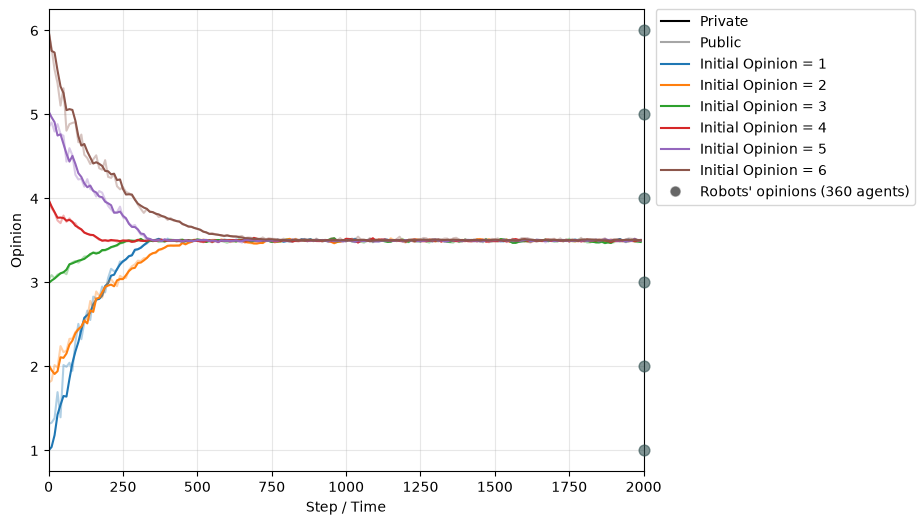

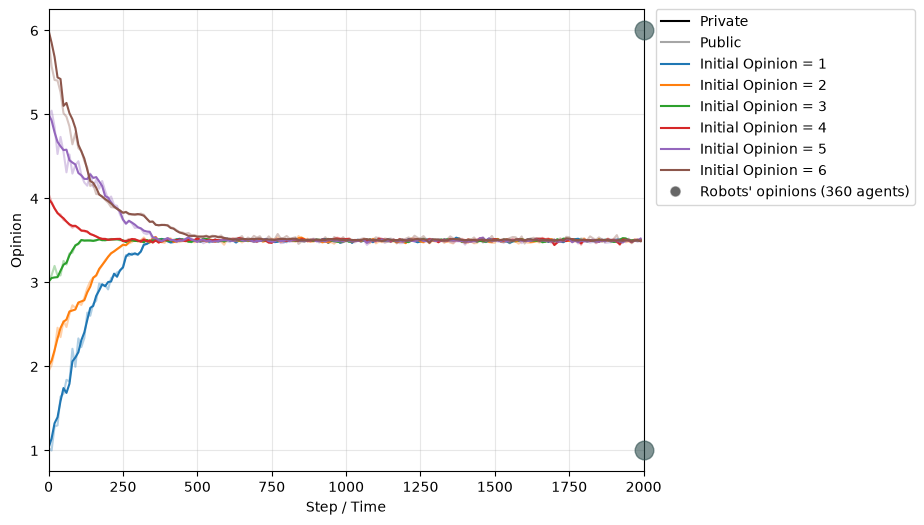

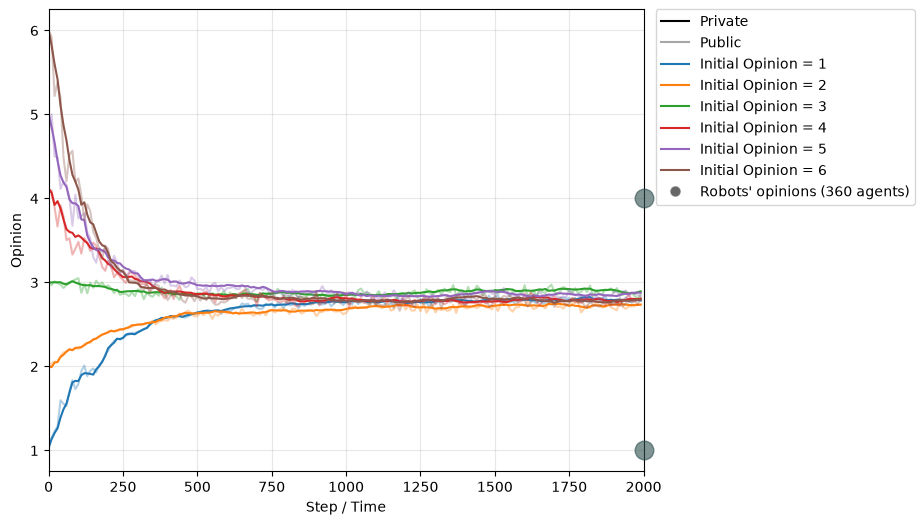

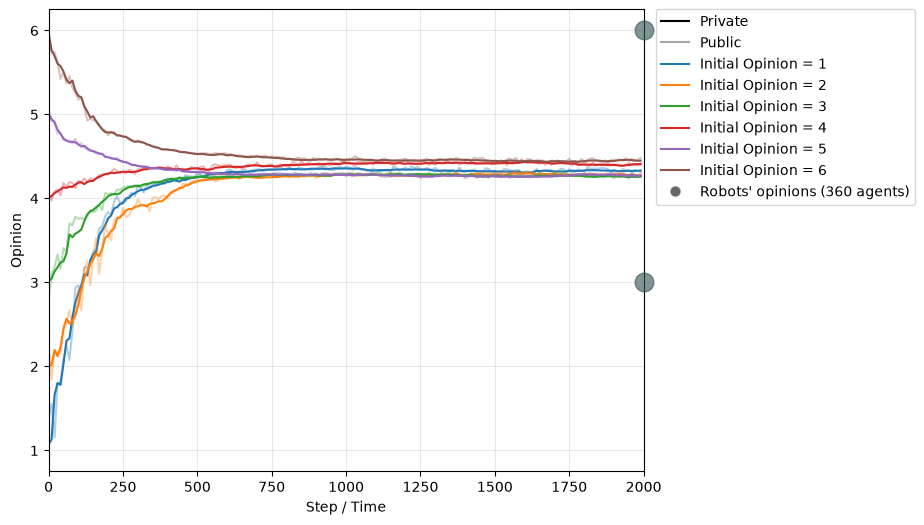

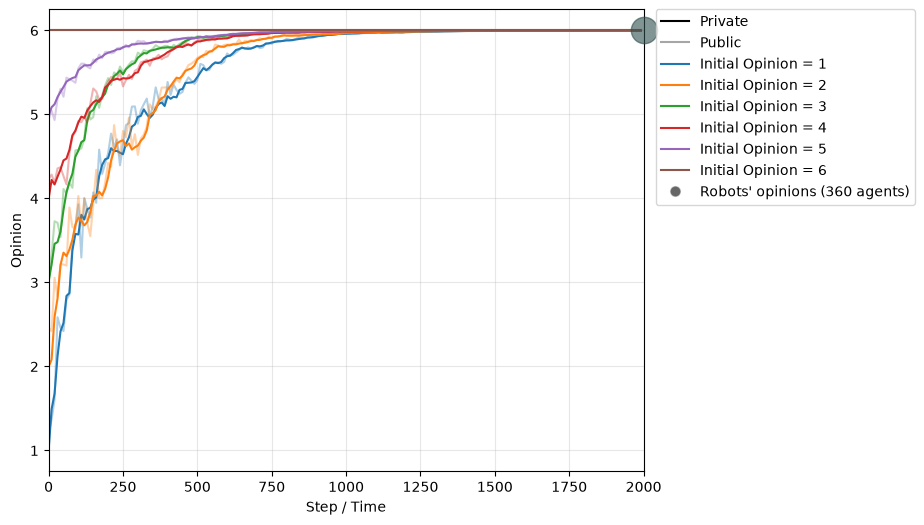

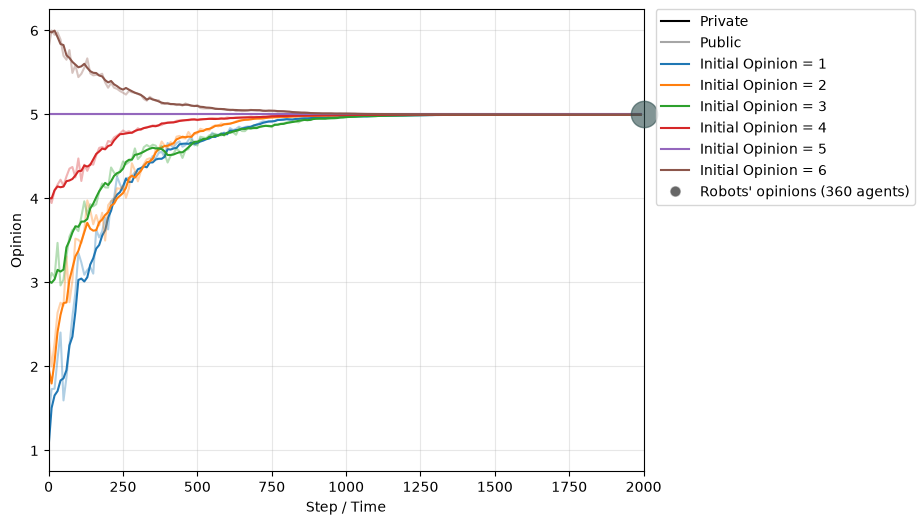

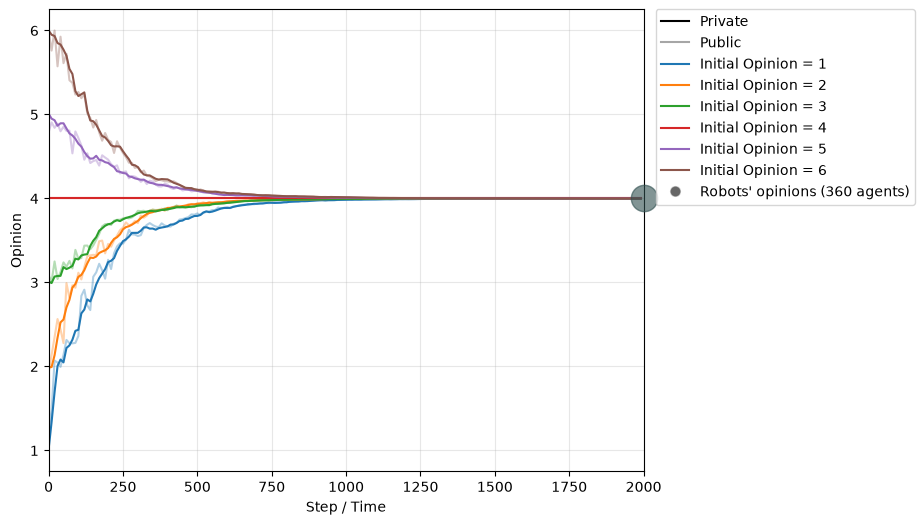

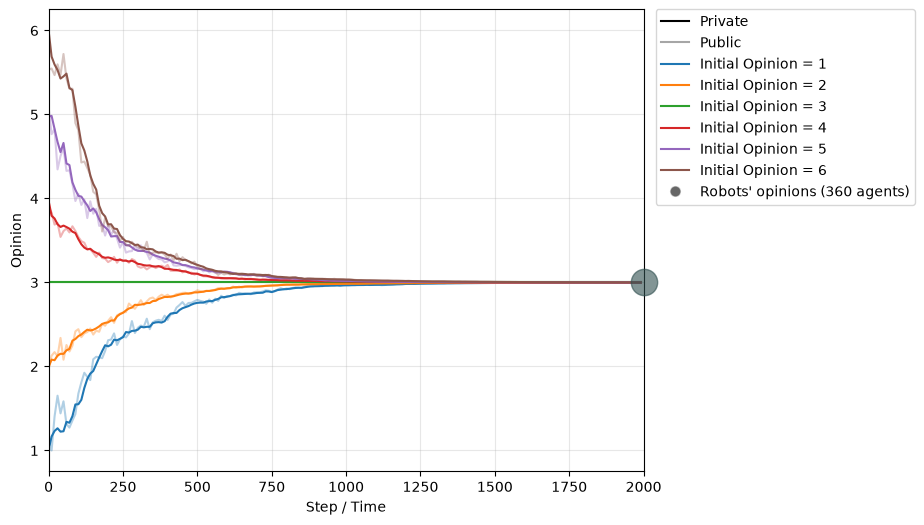

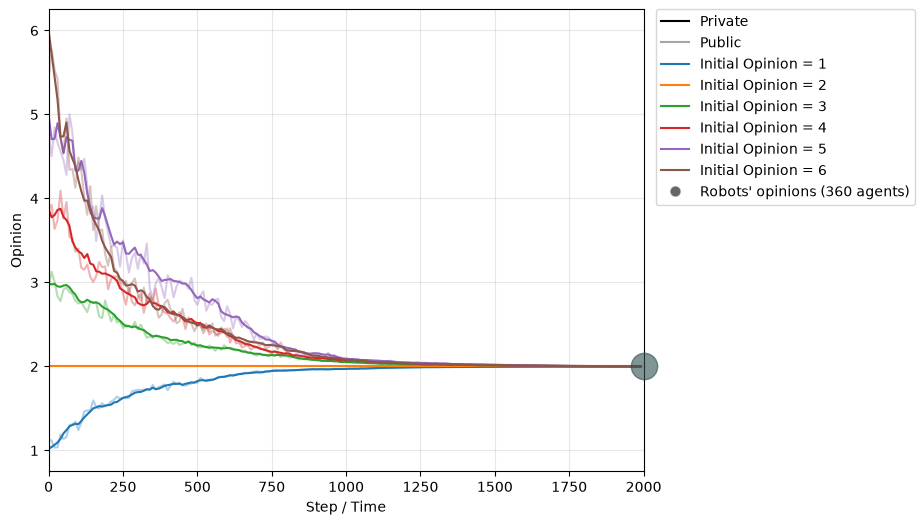

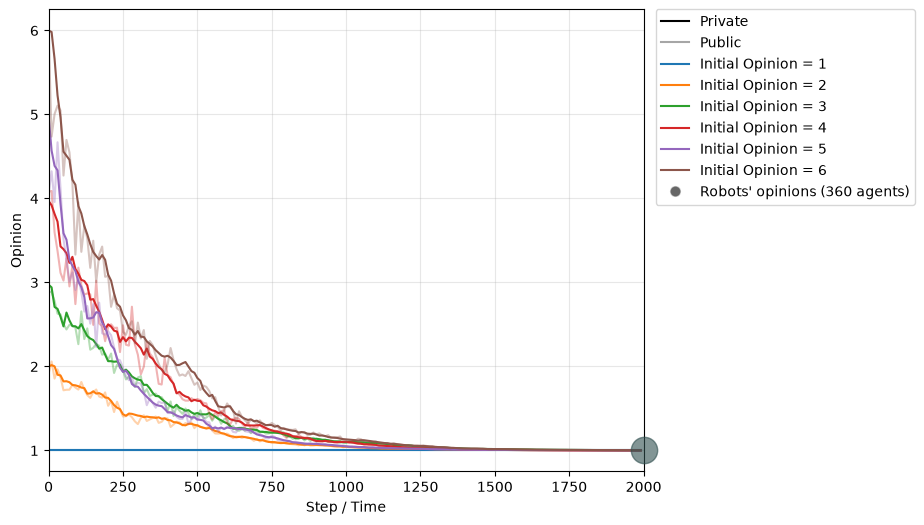

In [38]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import json


opinions_agents = { "all_opinions" : { "1": 0.1666, "2": 0.1667, "3": 0.1667, "4": 0.1667, "5": 0.1667, "6": 0.1666 },
           "1_6" : { "1": 0.5, "2": 0.0, "3": 0.0, "4": 0.0, "5": 0.0, "6": 0.5 },
           "1_4" : { "1": 0.5, "2": 0.0, "3": 0.0, "4": 0.5, "5": 0.0, "6": 0.0 },
            "3_6" : { "1": 0.0, "2": 0.0, "3": 0.5, "4": 0.0, "5": 0.0, "6": 0.5 },
           "6" : { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 },
           "5" : { "1": 0, "2": 0, "3": 0, "4": 0, "5": 1, "6": 0 },
           "4" : { "1": 0, "2": 0, "3": 0, "4": 1, "5": 0, "6": 0 },
           "3" : { "1": 0, "2": 0, "3": 1, "4": 0, "5": 0, "6": 0 },
           "2" : { "1": 0, "2": 1, "3": 0, "4": 0, "5": 0, "6": 0 },
           "1" : { "1": 1, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0 }}

noises = {"susc":0.080, "conf":0.087, "w":0.077}


for op_ag in opinions_agents.keys():

    weights = {}
    conf = {}
    susc = {}
    for row in weights_rows:
   
        ag = row["agent"]
        kn = row["knowledge"]
        oh = row["opinion_human"]
    
        weights.setdefault(ag, {}) \
               .setdefault(kn, {})[oh] = {
                    "w_fav": round(row["w_fav"], 3),
                    "w_cont": round(row["w_cont"], 3)
               }
    
    for row in conformity_rows:
        ag = row["agent"]
        conf[ag] = row["conformity"]
    
    for row in susceptibility_rows:
        ag = row["agent"]
        susc[ag] = row["susceptibility"]
    
    
    
    populations = []
    opinions = [{ "1": 1, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 1, "3": 0, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 1, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 0, "4": 1, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 0, "4": 0, "5": 1, "6": 0 },
               { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 }]
    for op in opinions:
        data = {
            "humans": {
                "number": 1,
                "opinions": op,
                "knowledge": { "low": 1, "high": 0 }
            },
            "influencers": {
                "robots": {
                    "number": 360,
                    "opinions": opinions_agents[op_ag]
                },
                "virtuals": {
                    "number": 0,
                    "opinions": { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 }
                },
                "articles": {
                    "number": 0,
                    "opinions": { "1": 0, "2": 0, "3": 0.5, "4": 0.5, "5": 0, "6": 0 }
                }
            }
        }
        
        populations.append(Population(data, weights, susc, conf, noises["susc"], noises["conf"], noises["w"]))
    
    priv_opinion = []
    pub_opinion = []
    
    for p in populations:
        aux_priv = []
        aux_pub = []
        for i in range(2000):
            p.step()
            if(i%10 == 0):
                aux_priv.append(p.get_priv_opinions()[0])
                aux_pub.append(p.get_public_opinions()[0])
        priv_opinion.append(aux_priv)
        pub_opinion.append(aux_pub)
    
    # --- plot ---
    # --- plot ---
    cmap = plt.get_cmap("tab10")
    colors = [cmap(i) for i in range(len(populations))]
    
    # eixo x com os steps reais (0, 10, 20, ..., 1990)
    steps = [i * 10 for i in range(len(priv_opinion[0]))]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for priv_op, pub_op, color in zip(priv_opinion, pub_opinion, colors):
        ax.plot(steps, priv_op, color=color, linestyle="-", linewidth=1.5, alpha=1.0)
        ax.plot(steps, pub_op, color=color, linestyle="-", linewidth=1.5, alpha=0.35)
    
    ax.set_xlabel("Step / Time")
    ax.set_ylabel("Opinion")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 2000)          # eixo x vai até 2000
    
    # --- opiniões dos agentes (robôs) à direita do gráfico ---
    robot_ops = data["influencers"]["robots"]["opinions"]
    n_robots = data["influencers"]["robots"]["number"]
    
    x_dots = 2000         # ligeiramente fora da área das linhas
    for k, frac in robot_ops.items():
        ax.scatter(
            x_dots, int(k),
            s=frac * n_robots * 1,
            color="darkSlateGray", marker="o", alpha=0.6,
            clip_on=False, zorder=5
        )
    
        # --- parâmetros usados (pesos, suscetibilidade, conformidade) ---
    AGENT = "robots"        # <-- ajusta para a chave do agente humano nos teus JSON
    KNOWLEDGE = "low"      # o humano da simulação tem knowledge low = 1
    
    w = weights[AGENT][KNOWLEDGE]   # {oh: {"w_fav": .., "w_cont": ..}}
    
    def text_entry(label):
        # entrada só de texto: sem linha nem marcador
        return Line2D([], [], linestyle="none", marker="None", label=label)
    
    params_handles = []
    for oh_key in sorted(w):               # as duas chaves de opinion_human (<3.5 e >=3.5)
        params_handles.append(text_entry(
            f"Human {oh_key}:  w_fav =\n {w[oh_key]['w_fav']} + {noises['w']},\n  w_cont = {w[oh_key]['w_cont']} + {noises['w']}"
        ))
    params_handles.append(text_entry(f"Susceptibility = {susc[AGENT]} + {noises['susc']}"))
    params_handles.append(text_entry(f"Conformity = {conf[AGENT]} + {noises['conf']}"))

    
    
    # --- legendas ---
    style_legend = [
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, alpha=1.0, label="Private"),
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, alpha=0.35, label="Public"),
    ]
    
    color_legend = [
        Line2D([0], [0], color=colors[i], linestyle="-",
               linewidth=1.5, label=f"Initial Opinion = {i+1}")
        for i in range(len(populations))
    ]
    
    robots_legend = [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor="black", alpha=0.6,
               markersize=8,
               label=f"Robots' opinions ({n_robots} agents)")
    ]
    
    # Juntar todas as legendas
    all_handles = style_legend + color_legend + robots_legend
    
    ax.legend(
        handles=all_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0,
        frameon=True
    )
    
    # Reservar espaço para a legenda
    fig.subplots_adjust(right=0.72)
    
    plt.savefig(
        "./plots_models_topic/general/robots/" + op_ag + ".png",
        bbox_inches="tight",
        dpi=300
    )

#### 1 vs 360 virtual agents

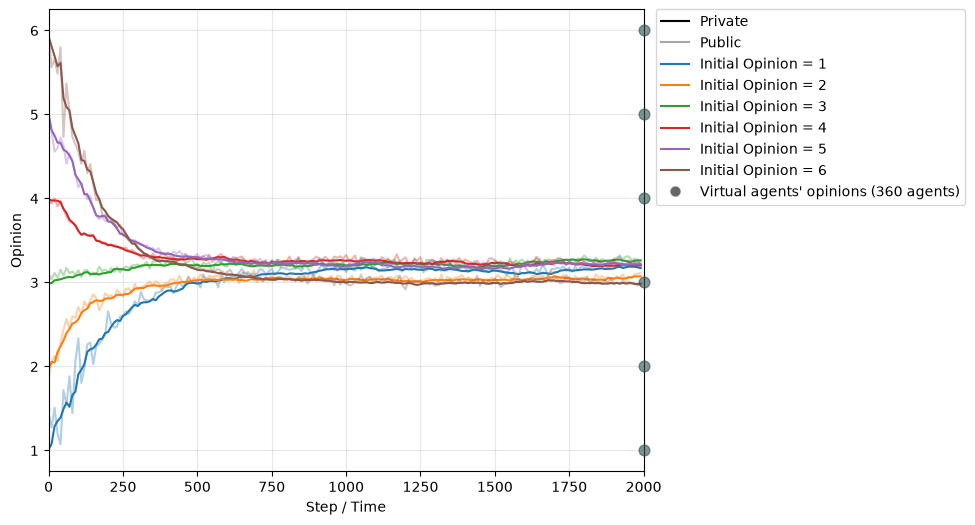

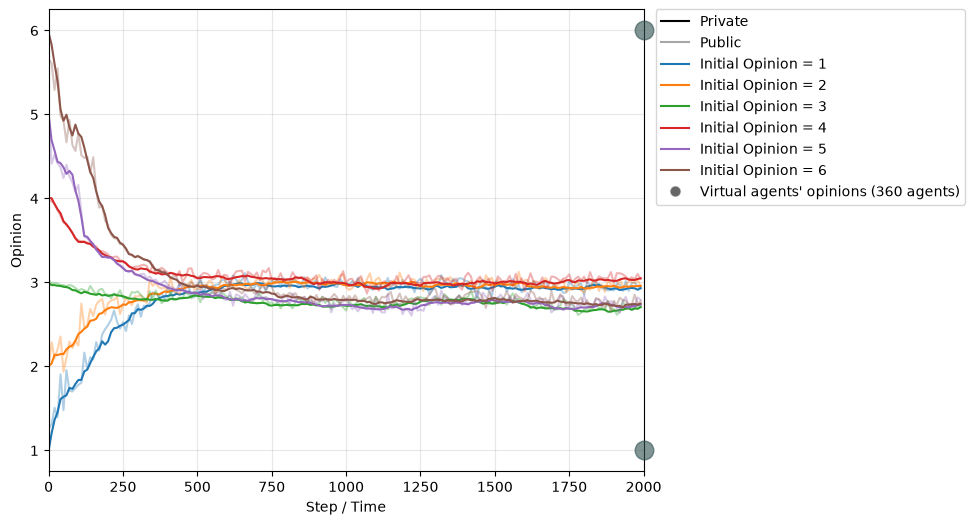

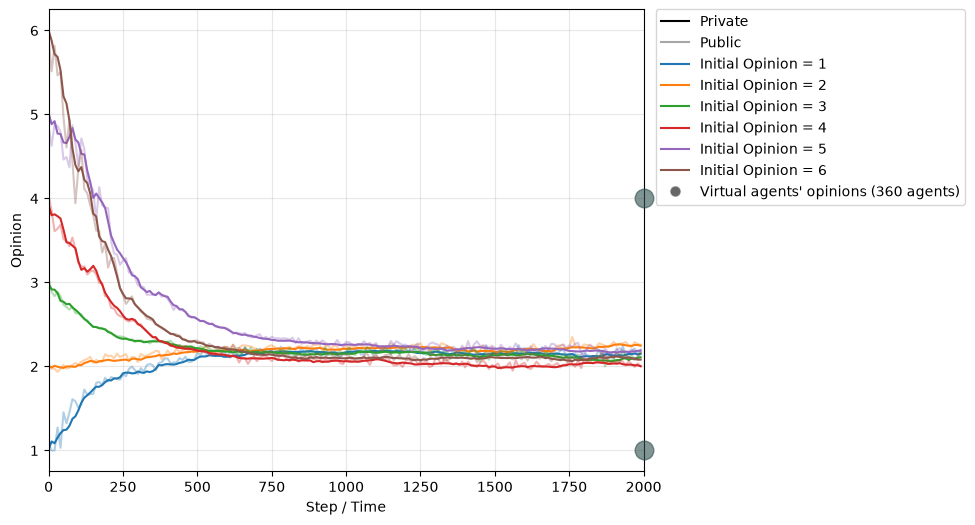

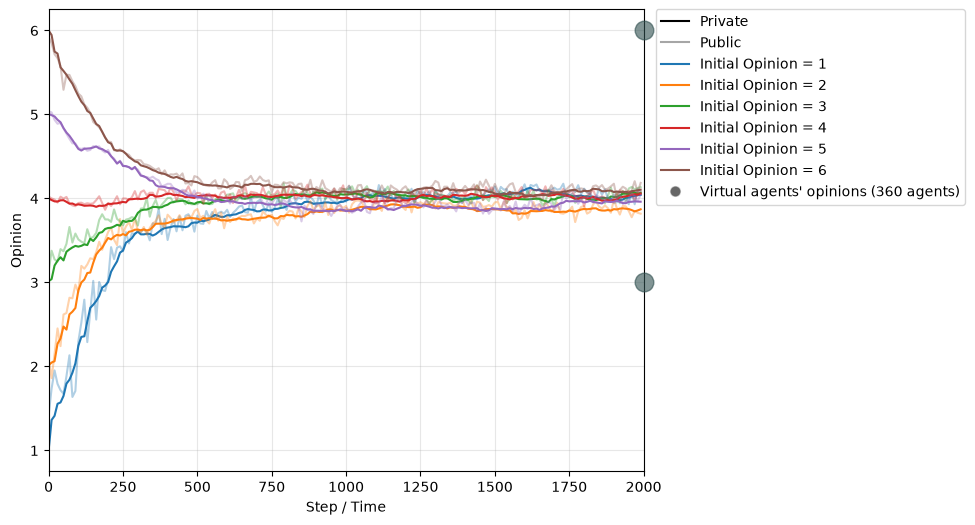

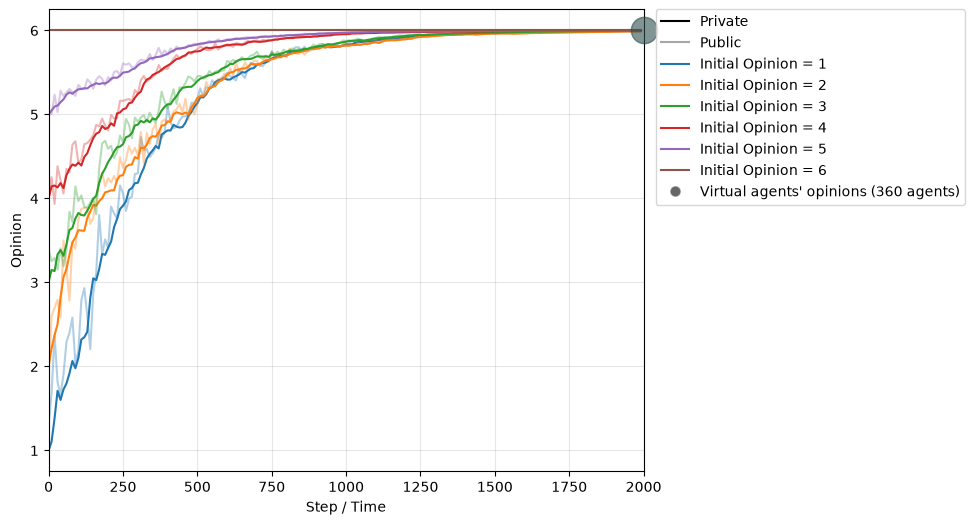

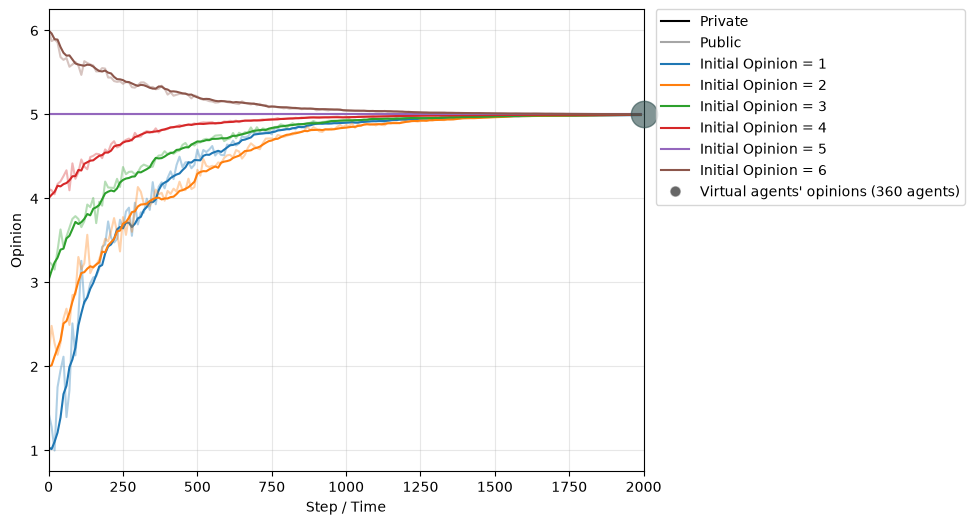

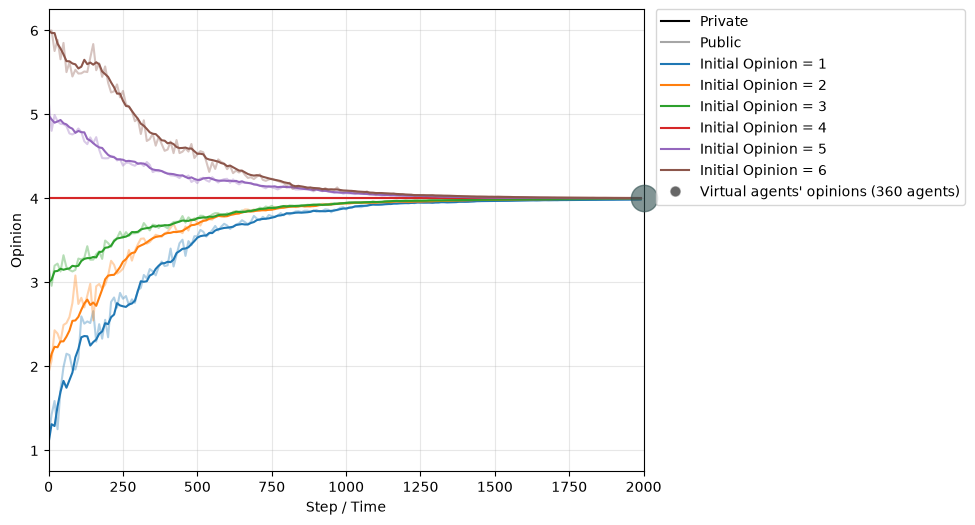

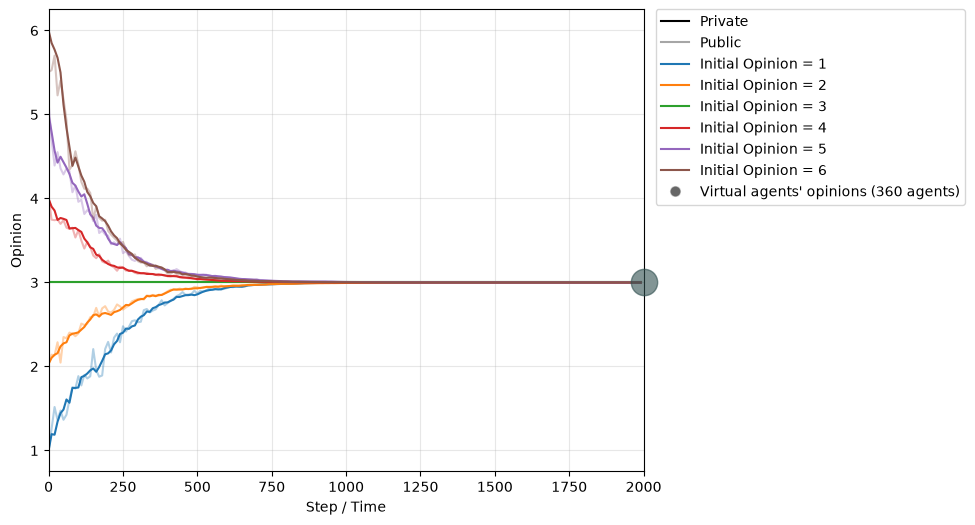

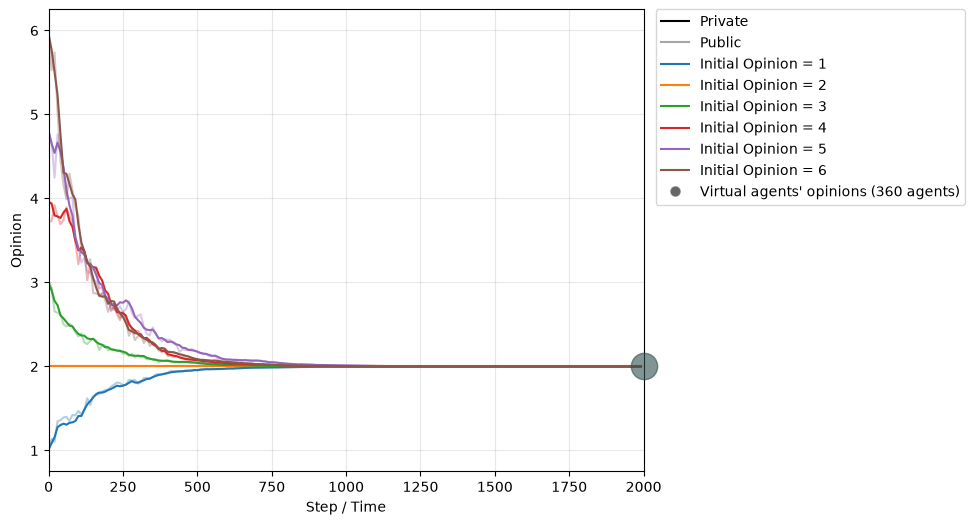

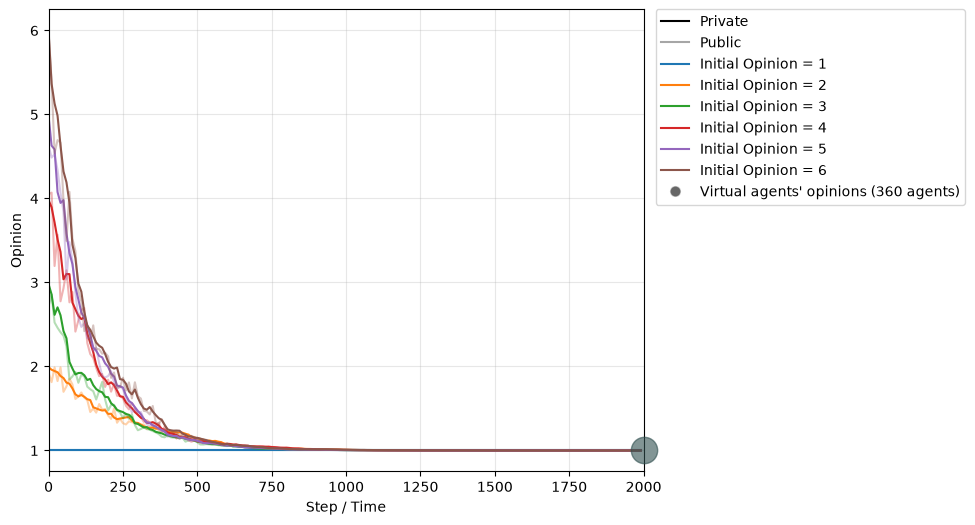

In [40]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import json


opinions_agents = { "all_opinions" : { "1": 0.1666, "2": 0.1667, "3": 0.1667, "4": 0.1667, "5": 0.1667, "6": 0.1666 },
           "1_6" : { "1": 0.5, "2": 0.0, "3": 0.0, "4": 0.0, "5": 0.0, "6": 0.5 },
           "1_4" : { "1": 0.5, "2": 0.0, "3": 0.0, "4": 0.5, "5": 0.0, "6": 0.0 },
            "3_6" : { "1": 0.0, "2": 0.0, "3": 0.5, "4": 0.0, "5": 0.0, "6": 0.5 },
           "6" : { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 },
           "5" : { "1": 0, "2": 0, "3": 0, "4": 0, "5": 1, "6": 0 },
           "4" : { "1": 0, "2": 0, "3": 0, "4": 1, "5": 0, "6": 0 },
           "3" : { "1": 0, "2": 0, "3": 1, "4": 0, "5": 0, "6": 0 },
           "2" : { "1": 0, "2": 1, "3": 0, "4": 0, "5": 0, "6": 0 },
           "1" : { "1": 1, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0 }}


noises = {"susc":0.080, "conf":0.087, "w":0.077}


for op_ag in opinions_agents.keys():

    weights = {}
    conf = {}
    susc = {}
    for row in weights_rows:
   
        ag = row["agent"]
        kn = row["knowledge"]
        oh = row["opinion_human"]
    
        weights.setdefault(ag, {}) \
               .setdefault(kn, {})[oh] = {
                    "w_fav": round(row["w_fav"], 3),
                    "w_cont": round(row["w_cont"], 3)
               }
    
    for row in conformity_rows:
        ag = row["agent"]
        conf[ag] = row["conformity"]
    
    for row in susceptibility_rows:
        ag = row["agent"]
        susc[ag] = row["susceptibility"]
    
    
    
    populations = []
    opinions = [{ "1": 1, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 1, "3": 0, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 1, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 0, "4": 1, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 0, "4": 0, "5": 1, "6": 0 },
               { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 }]
    for op in opinions:
        data = {
            "humans": {
                "number": 1,
                "opinions": op,
                "knowledge": { "low": 1, "high": 0 }
            },
            "influencers": {
                "robots": {
                    "number": 0,
                    "opinions": { "1": 0, "2": 0, "3": 0.5, "4": 0.5, "5": 0, "6": 0 }
                },
                "virtuals": {
                    "number": 360,
                    "opinions": opinions_agents[op_ag]
                },
                "articles": {
                    "number": 0,
                    "opinions": { "1": 0, "2": 0, "3": 0.5, "4": 0.5, "5": 0, "6": 0 }
                }
            }
        }
        
        populations.append(Population(data, weights, susc, conf, noises["susc"], noises["conf"], noises["w"]))
    
    priv_opinion = []
    pub_opinion = []
    
    for p in populations:
        aux_priv = []
        aux_pub = []
        for i in range(2000):
            p.step()
            if(i%10 == 0):
                aux_priv.append(p.get_priv_opinions()[0])
                aux_pub.append(p.get_public_opinions()[0])
        priv_opinion.append(aux_priv)
        pub_opinion.append(aux_pub)
    
    # --- plot ---
    # --- plot ---
    cmap = plt.get_cmap("tab10")
    colors = [cmap(i) for i in range(len(populations))]
    
    # eixo x com os steps reais (0, 10, 20, ..., 1990)
    steps = [i * 10 for i in range(len(priv_opinion[0]))]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for priv_op, pub_op, color in zip(priv_opinion, pub_opinion, colors):
        ax.plot(steps, priv_op, color=color, linestyle="-", linewidth=1.5, alpha=1.0)
        ax.plot(steps, pub_op, color=color, linestyle="-", linewidth=1.5, alpha=0.35)
    
    ax.set_xlabel("Step / Time")
    ax.set_ylabel("Opinion")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 2000)          # eixo x vai até 2000
    
    # --- opiniões dos agentes (robôs) à direita do gráfico ---
    robot_ops = data["influencers"]["virtuals"]["opinions"]
    n_robots = data["influencers"]["virtuals"]["number"]
    
    x_dots = 2000         # ligeiramente fora da área das linhas
    for k, frac in robot_ops.items():
        ax.scatter(
            x_dots, int(k),
            s=frac * n_robots * 1,
            color="darkSlateGray", marker="o", alpha=0.6,
            clip_on=False, zorder=5
        )
    
        # --- parâmetros usados (pesos, suscetibilidade, conformidade) ---
    AGENT = "virtuals"        # <-- ajusta para a chave do agente humano nos teus JSON
    KNOWLEDGE = "low"      # o humano da simulação tem knowledge low = 1
    
    w = weights[AGENT][KNOWLEDGE]   # {oh: {"w_fav": .., "w_cont": ..}}
    
    def text_entry(label):
        # entrada só de texto: sem linha nem marcador
        return Line2D([], [], linestyle="none", marker="None", label=label)
    
    params_handles = []
    for oh_key in sorted(w):               # as duas chaves de opinion_human (<3.5 e >=3.5)
        params_handles.append(text_entry(
            f"Human {oh_key}:  w_fav =\n {w[oh_key]['w_fav']} + {noises['w']},\n  w_cont = {w[oh_key]['w_cont']} + {noises['w']}"
        ))
    params_handles.append(text_entry(f"Susceptibility = {susc[AGENT]} + {noises['susc']}"))
    params_handles.append(text_entry(f"Conformity = {conf[AGENT]} + {noises['conf']}"))

    
    
    # --- legendas ---
    style_legend = [
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, alpha=1.0, label="Private"),
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, alpha=0.35, label="Public"),
    ]
    
    color_legend = [
        Line2D([0], [0], color=colors[i], linestyle="-",
               linewidth=1.5, label=f"Initial Opinion = {i+1}")
        for i in range(len(populations))
    ]
    
    robots_legend = [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor="black", alpha=0.6,
               markersize=8,
               label=f"Virtual agents' opinions ({n_robots} agents)")
    ]
    
    # Juntar todas as legendas
    all_handles = style_legend + color_legend + robots_legend
    
    ax.legend(
        handles=all_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0,
        frameon=True
    )
    
    # Reservar espaço para a legenda
    fig.subplots_adjust(right=0.72)
    
    plt.savefig(
        "./plots_models_topic/general/virtuals/" + op_ag + ".png",
        bbox_inches="tight",
        dpi=300
    )

#### 1 vs 360 articles

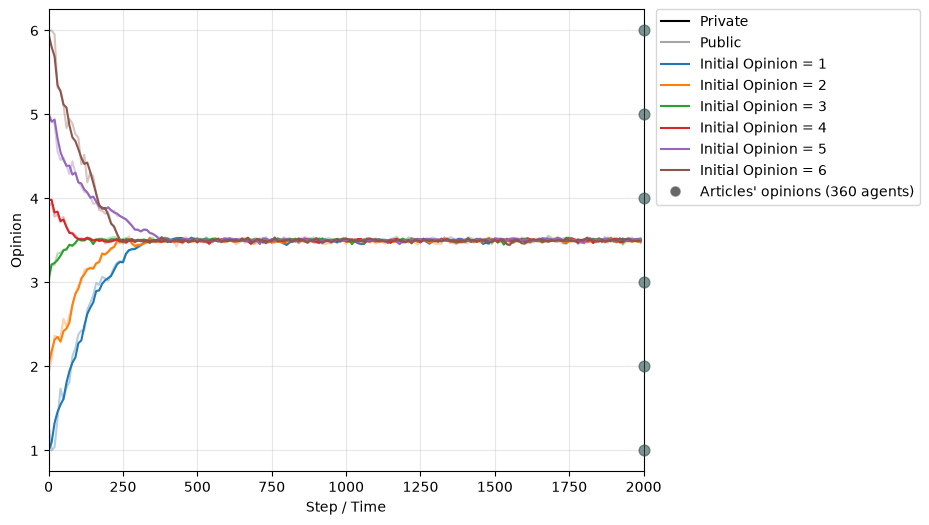

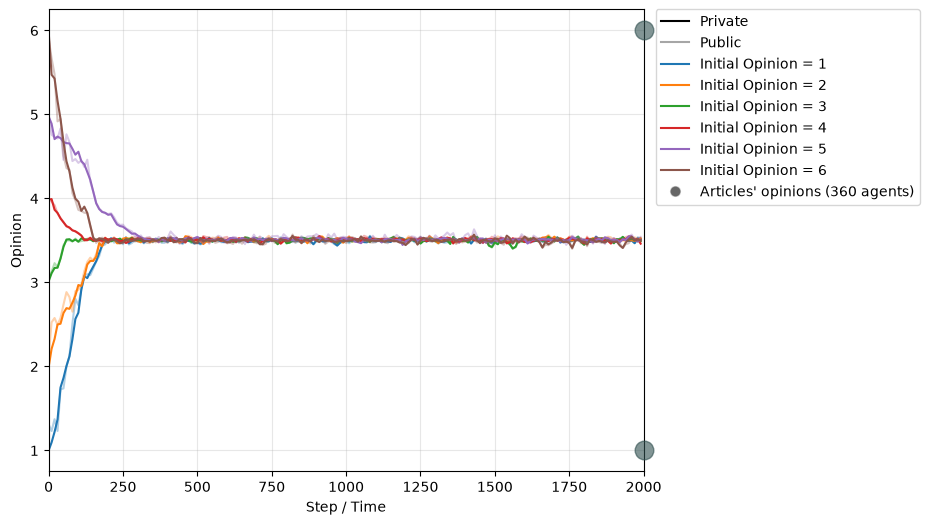

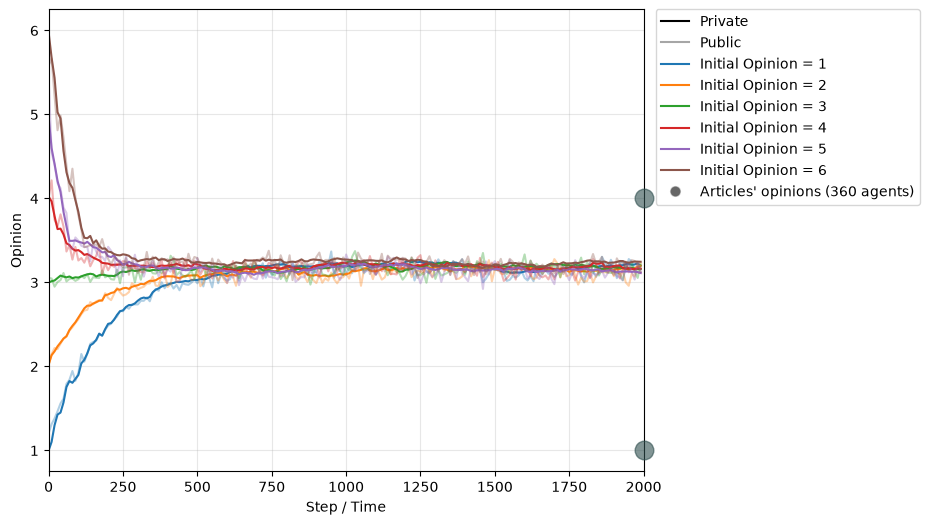

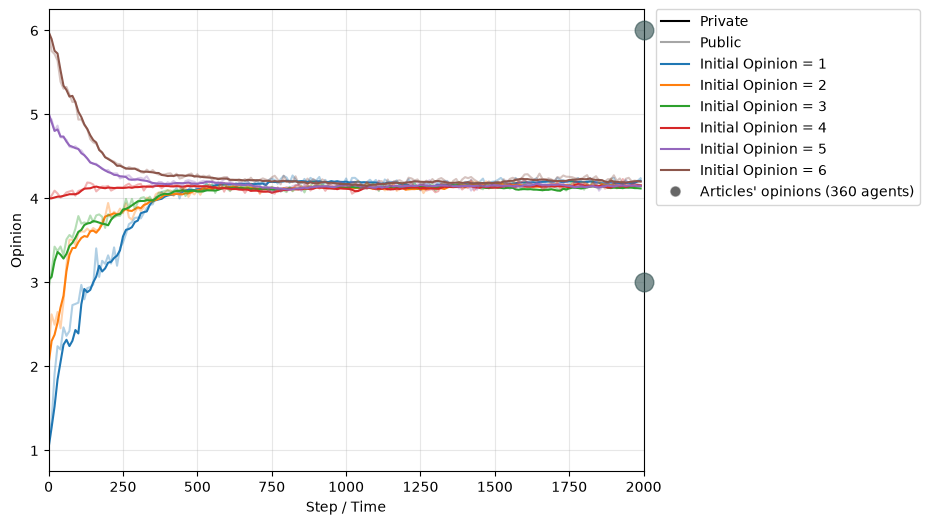

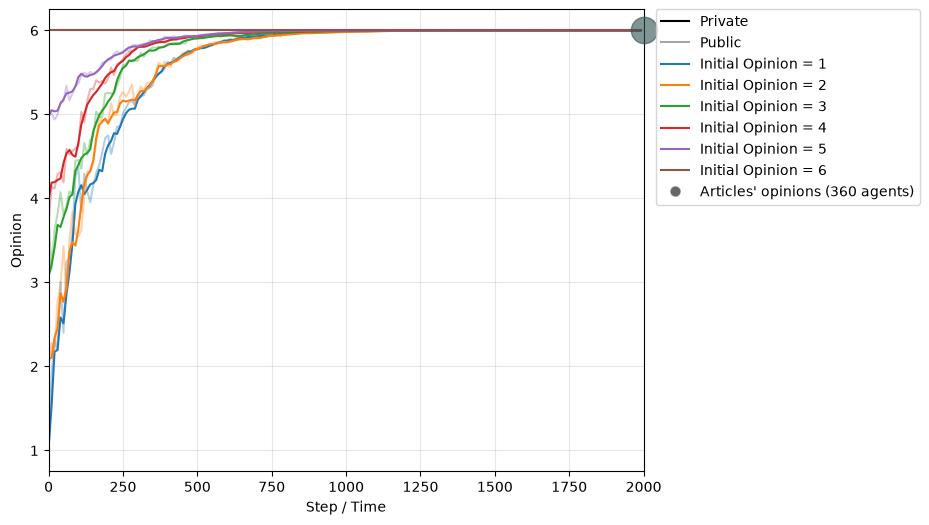

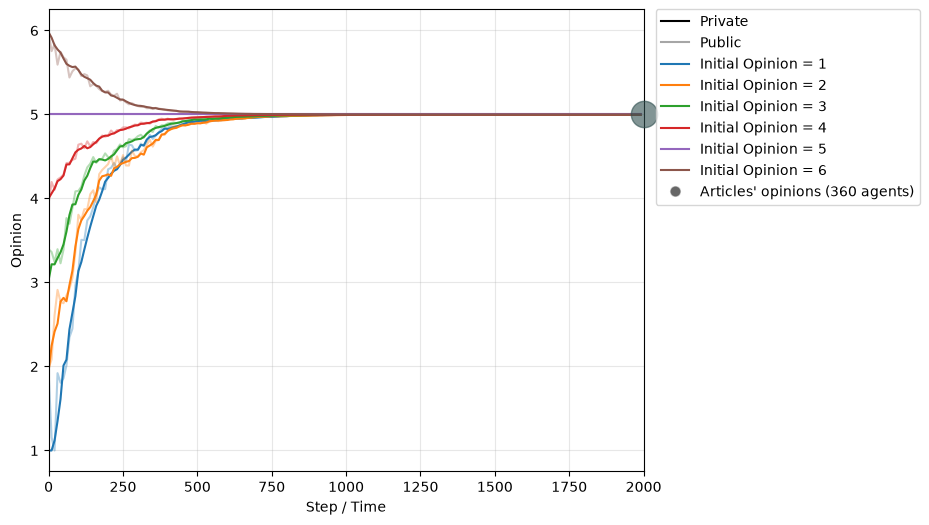

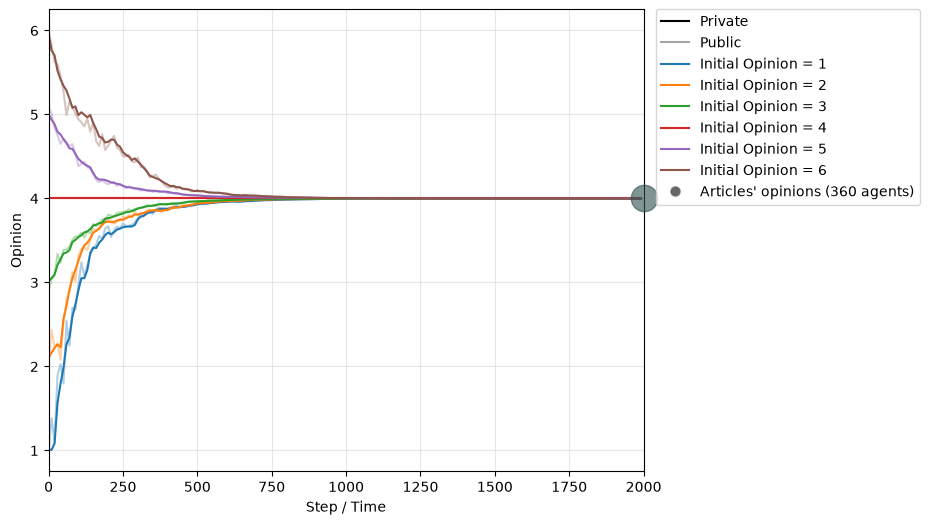

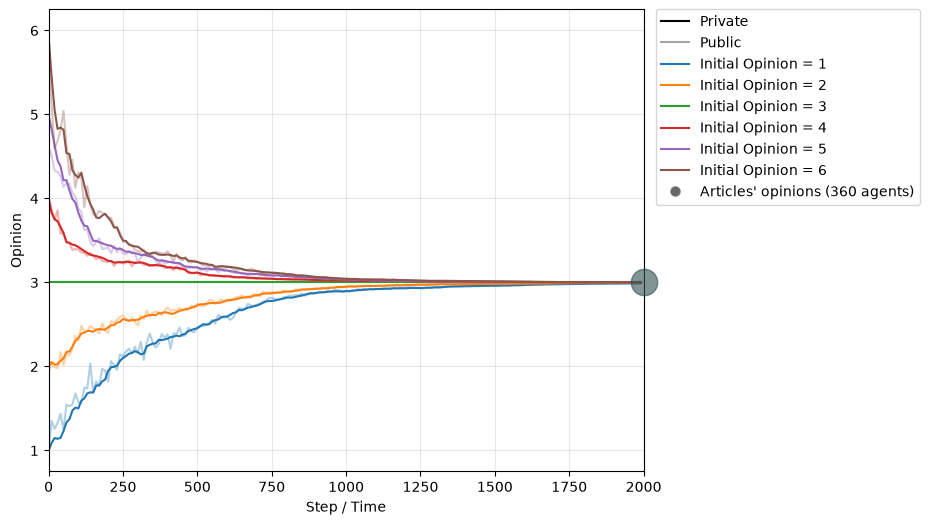

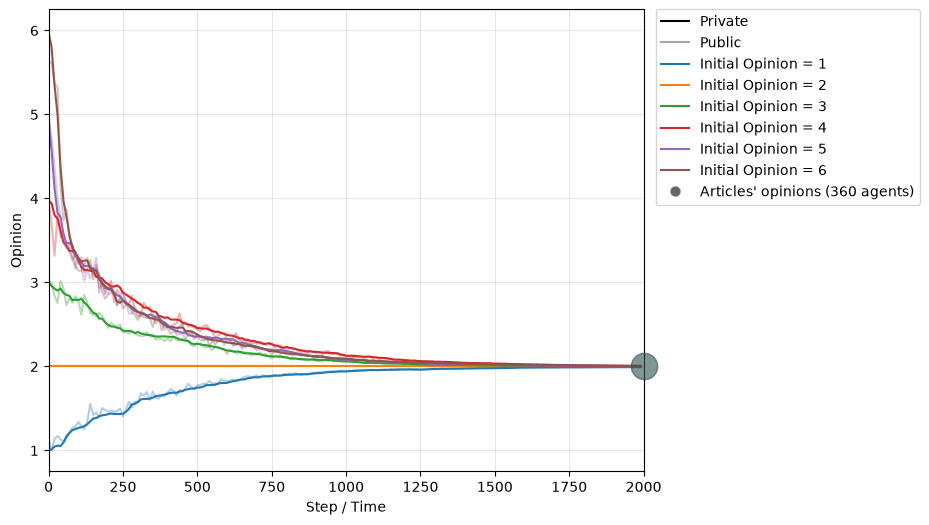

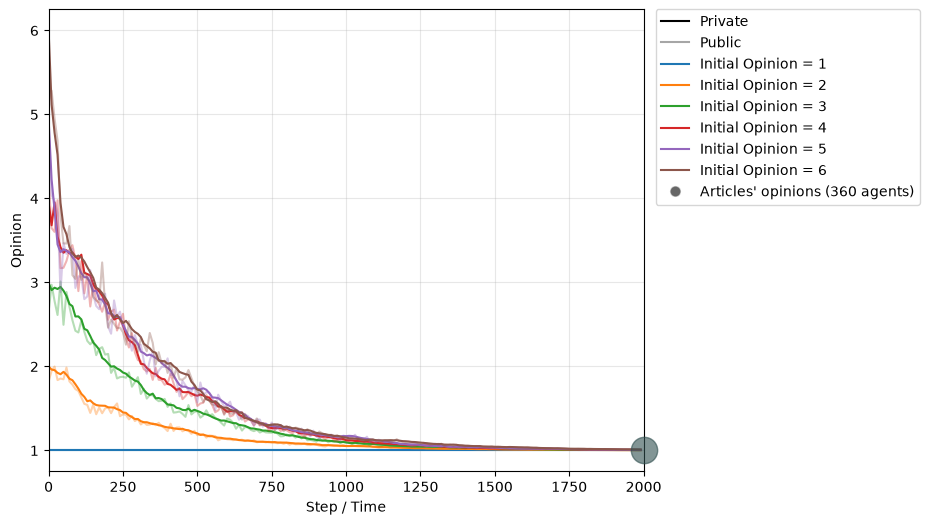

In [41]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import json


opinions_agents = { "all_opinions" : { "1": 0.1666, "2": 0.1667, "3": 0.1667, "4": 0.1667, "5": 0.1667, "6": 0.1666 },
           "1_6" : { "1": 0.5, "2": 0.0, "3": 0.0, "4": 0.0, "5": 0.0, "6": 0.5 },
           "1_4" : { "1": 0.5, "2": 0.0, "3": 0.0, "4": 0.5, "5": 0.0, "6": 0.0 },
            "3_6" : { "1": 0.0, "2": 0.0, "3": 0.5, "4": 0.0, "5": 0.0, "6": 0.5 },
           "6" : { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 },
           "5" : { "1": 0, "2": 0, "3": 0, "4": 0, "5": 1, "6": 0 },
           "4" : { "1": 0, "2": 0, "3": 0, "4": 1, "5": 0, "6": 0 },
           "3" : { "1": 0, "2": 0, "3": 1, "4": 0, "5": 0, "6": 0 },
           "2" : { "1": 0, "2": 1, "3": 0, "4": 0, "5": 0, "6": 0 },
           "1" : { "1": 1, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0 }}

noises = {"susc":0.080, "conf":0.087, "w":0.077}


for op_ag in opinions_agents.keys():

    weights = {}
    conf = {}
    susc = {}
    for row in weights_rows:
   
        ag = row["agent"]
        kn = row["knowledge"]
        oh = row["opinion_human"]
    
        weights.setdefault(ag, {}) \
               .setdefault(kn, {})[oh] = {
                    "w_fav": round(row["w_fav"], 3),
                    "w_cont": round(row["w_cont"], 3)
               }
    
    for row in conformity_rows:
        ag = row["agent"]
        conf[ag] = row["conformity"]
    
    for row in susceptibility_rows:
        ag = row["agent"]
        susc[ag] = row["susceptibility"]
    
    
    
    populations = []
    opinions = [{ "1": 1, "2": 0, "3": 0, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 1, "3": 0, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 1, "4": 0, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 0, "4": 1, "5": 0, "6": 0 },
                { "1": 0, "2": 0, "3": 0, "4": 0, "5": 1, "6": 0 },
               { "1": 0, "2": 0, "3": 0, "4": 0, "5": 0, "6": 1 }]
    for op in opinions:
        data = {
            "humans": {
                "number": 1,
                "opinions": op,
                "knowledge": { "low": 1, "high": 0 }
            },
            "influencers": {
                "robots": {
                    "number": 0,
                    "opinions": { "1": 0, "2": 0, "3": 0.5, "4": 0.5, "5": 0, "6": 0 }
                },
                "virtuals": {
                    "number": 0,
                    "opinions": { "1": 0, "2": 0, "3": 0.5, "4": 0.5, "5": 0, "6": 0 }
                },
                "articles": {
                    "number": 360,
                    "opinions": opinions_agents[op_ag]
                }
            }
        }
        
        populations.append(Population(data, weights, susc, conf, noises["susc"], noises["conf"], noises["w"]))
    
    priv_opinion = []
    pub_opinion = []
    
    for p in populations:
        aux_priv = []
        aux_pub = []
        for i in range(2000):
            p.step()
            if(i%10 == 0):
                aux_priv.append(p.get_priv_opinions()[0])
                aux_pub.append(p.get_public_opinions()[0])
        priv_opinion.append(aux_priv)
        pub_opinion.append(aux_pub)
    
    # --- plot ---
    # --- plot ---
    cmap = plt.get_cmap("tab10")
    colors = [cmap(i) for i in range(len(populations))]
    
    # eixo x com os steps reais (0, 10, 20, ..., 1990)
    steps = [i * 10 for i in range(len(priv_opinion[0]))]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for priv_op, pub_op, color in zip(priv_opinion, pub_opinion, colors):
        ax.plot(steps, priv_op, color=color, linestyle="-", linewidth=1.5, alpha=1.0)
        ax.plot(steps, pub_op, color=color, linestyle="-", linewidth=1.5, alpha=0.35)
    
    ax.set_xlabel("Step / Time")
    ax.set_ylabel("Opinion")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 2000)          # eixo x vai até 2000
    
    # --- opiniões dos agentes (robôs) à direita do gráfico ---
    robot_ops = data["influencers"]["articles"]["opinions"]
    n_robots = data["influencers"]["articles"]["number"]
    
    x_dots = 2000         # ligeiramente fora da área das linhas
    for k, frac in robot_ops.items():
        ax.scatter(
            x_dots, int(k),
            s=frac * n_robots * 1,
            color="darkSlateGray", marker="o", alpha=0.6,
            clip_on=False, zorder=5
        )
    
        # --- parâmetros usados (pesos, suscetibilidade, conformidade) ---
    AGENT = "articles"        # <-- ajusta para a chave do agente humano nos teus JSON
    KNOWLEDGE = "low"      # o humano da simulação tem knowledge low = 1
    
    w = weights[AGENT][KNOWLEDGE]   # {oh: {"w_fav": .., "w_cont": ..}}
    
    def text_entry(label):
        # entrada só de texto: sem linha nem marcador
        return Line2D([], [], linestyle="none", marker="None", label=label)
    
    params_handles = []
    for oh_key in sorted(w):               # as duas chaves de opinion_human (<3.5 e >=3.5)
        params_handles.append(text_entry(
            f"Human {oh_key}:  w_fav =\n {w[oh_key]['w_fav']} + {noises['w']},\n  w_cont = {w[oh_key]['w_cont']} + {noises['w']}"
        ))
    params_handles.append(text_entry(f"Susceptibility = {susc[AGENT]} + {noises['susc']}"))
    params_handles.append(text_entry(f"Conformity = {conf[AGENT]} + {noises['conf']}"))

    
    
     # --- legendas ---
    style_legend = [
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, alpha=1.0, label="Private"),
        Line2D([0], [0], color="black", linestyle="-",
               linewidth=1.5, alpha=0.35, label="Public"),
    ]
    
    color_legend = [
        Line2D([0], [0], color=colors[i], linestyle="-",
               linewidth=1.5, label=f"Initial Opinion = {i+1}")
        for i in range(len(populations))
    ]
    
    robots_legend = [
        Line2D([0], [0], marker="o", color="w",
               markerfacecolor="black", alpha=0.6,
               markersize=8,
               label=f"Articles' opinions ({n_robots} agents)")
    ]
    
    # Juntar todas as legendas
    all_handles = style_legend + color_legend + robots_legend
    
    ax.legend(
        handles=all_handles,
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0,
        frameon=True
    )
    
    # Reservar espaço para a legenda
    fig.subplots_adjust(right=0.72)
    
    plt.savefig(
        "./plots_models_topic/general/articles/" + op_ag + ".png",
        bbox_inches="tight",
        dpi=300
    )